# OSMI Mental Health in Tech 2016 – Technische Fallstudienanalyse

**IU DLBDSMLUSL01_D · Unsupervised Learning und Feature Engineering**

Dieses Notebook dokumentiert die explorative Analyse des Datensatzes *OSMI Mental Health in Tech Survey 2016*. Ziel ist es, mithilfe unüberwachter Lernverfahren unterschiedliche Wahrnehmungen betrieblicher Unterstützungsangebote im Bereich der psychischen Gesundheit zu identifizieren und daraus mögliche Handlungsempfehlungen für das Personalmanagement abzuleiten.

Die Analyse umfasst die explorative Datenanalyse, Datenbereinigung, das Feature Engineering, die Anwendung und den Vergleich von K-Means und k-Modes, Stabilitäts- und Sensitivitätsprüfungen, Verfahren zur Dimensionsreduktion sowie die Visualisierung und Interpretation der Cluster.

Die Ergebnisse dienen der explorativen Beschreibung betrieblicher Unterstützungsbedingungen und ermöglichen weder medizinische Diagnosen noch kausale Schlussfolgerungen. Da der verwendete Datensatz keine nachweislich repräsentative Stichprobe aller Technologieunternehmen darstellt, ist die Übertragbarkeit der Ergebnisse eingeschränkt. Die Clusternummern sind ausschließlich algorithmische Kennzeichnungen und stellen keine qualitative Rangfolge dar.

In [ ]:
%pip -q install "kmodes==0.12.2"

In [ ]:
import io, zipfile, pathlib, platform, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, adjusted_rand_score, normalized_mutual_info_score,
                             calinski_harabasz_score, davies_bouldin_score, pairwise_distances)
from kmodes.kmodes import KModes
SEED=42
OUT=pathlib.Path('results'); OUT.mkdir(exist_ok=True)
import sklearn, scipy, kmodes, importlib.metadata
print('Python:',platform.python_version(),'| pandas:',pd.__version__,
      '| numpy:',np.__version__,'| scikit-learn:',sklearn.__version__,
      '| scipy:',scipy.__version__,'| kmodes:',importlib.metadata.version('kmodes'))

candidates=[pathlib.Path('/content/archive (1).zip'),pathlib.Path('archive (1).zip'),pathlib.Path('/mnt/data/archive (1).zip')]
source=next((p for p in candidates if p.is_file()),None)
if source is None:
    from google.colab import files
    uploaded=files.upload()
    names=[name for name in uploaded if name.lower().endswith('.zip')]
    if len(names)!=1: raise FileNotFoundError('Genau eine Original-OSMI-ZIP-Datei auswählen.')
    source=pathlib.Path(names[0])
print('OSMI-Quelldatei:', source.name)
with zipfile.ZipFile(source) as archive:
    names=[p for p in archive.namelist() if p.endswith('mental-heath-in-tech-2016_20161114.csv')]
    if len(names)!=1: raise ValueError('CSV mental-heath-in-tech-2016_20161114.csv nicht eindeutig gefunden.')
    data=pd.read_csv(io.BytesIO(archive.read(names[0])))
assert data.shape==(1433,63),f'Unerwartete Datenform: {data.shape}'
df=data.loc[data['Are you self-employed?'].eq(0)].reset_index(drop=True).copy()
assert df.shape==(1146,63)
print('Original:',data.shape,'| abhängig Beschäftigte:',df.shape)

Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | scikit-learn: 1.6.1 | scipy: 1.16.3 | kmodes: 0.12.2


Saving archive (1).zip to archive (1).zip
OSMI-Quelldatei: archive (1).zip
Original: (1433, 63) | abhängig Beschäftigte: (1146, 63)


## 1. EDA und Fehlwertmechanismus

Die Stichprobe wird auf Beschäftigte mit Arbeitgeber beschränkt, weil das HR-Szenario diese Gruppe betrifft. Im Fragebogen sind bestimmte Folgefragen nur für Selbstständige oder bei bestimmten Antworten vorgesehen (**strukturelles Fehlen**). Diese Antworten dürfen nicht pauschal imputiert werden. Andere leere Angaben sind gesondert zu interpretieren. Die Inventur listet alle 63 Ausgangsspalten; es werden keine personenbezogenen Einzelzeilen exportiert.

Fehlwertanteil bei Beschäftigten über alle Fragen: 22.01 %
Vollständige Spalten: 32 | Vollständig leere Spalten: 8
Vollständig leere Fragen gehören zu anderen Fragebogenpfaden; die einzelnen Felder sind in der EDA-CSV dokumentiert.


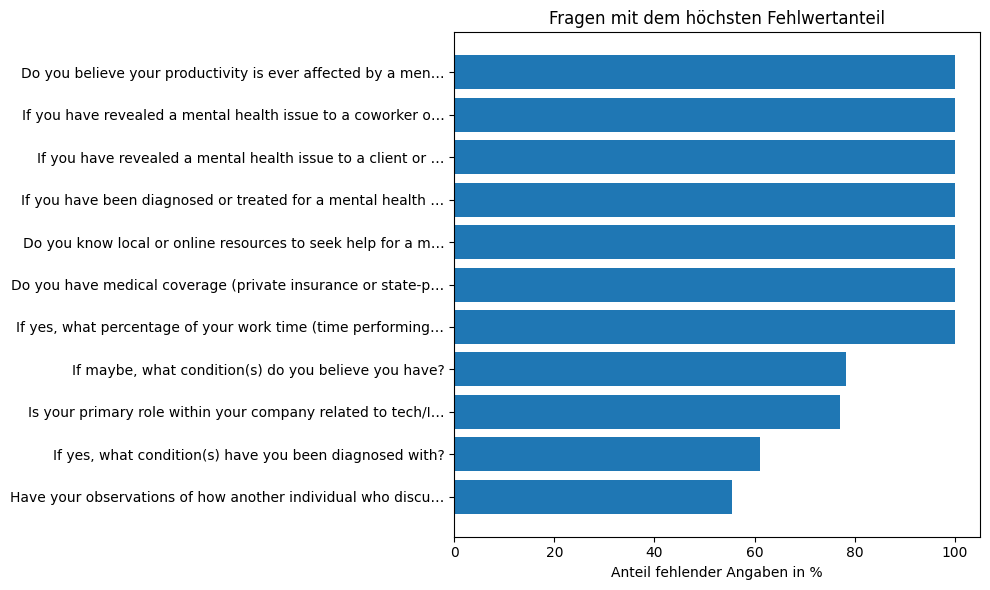

In [ ]:
summary=pd.DataFrame([{'Merkmal':c,'Datentyp':str(data[c].dtype),
    'Fehlend_gesamt':int(data[c].isna().sum()),
    'Fehlend_Beschaeftigte':int(df[c].isna().sum()),
    'Anteil_fehlend_Beschaeftigte_%':round(100*df[c].isna().mean(),2),
    'Unterschiedliche_Werte':int(df[c].nunique(dropna=True))} for c in data.columns])
summary.to_csv(OUT/'eda_63_merkmale.csv',index=False)
self_only=[c for c in df if df[c].isna().all()]
print('Fehlwertanteil bei Beschäftigten über alle Fragen:',round(100*df.isna().to_numpy().mean(),2),'%')
print('Vollständige Spalten:',df.notna().all().sum(),'| Vollständig leere Spalten:',len(self_only))
print('Vollständig leere Fragen gehören zu anderen Fragebogenpfaden; die einzelnen Felder sind in der EDA-CSV dokumentiert.')
plotdf=summary.sort_values('Anteil_fehlend_Beschaeftigte_%',ascending=False).head(12).iloc[::-1]
shortlabels=[s[:58]+'…' if len(s)>58 else s for s in plotdf.Merkmal]
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(shortlabels,plotdf['Anteil_fehlend_Beschaeftigte_%'])
ax.set(xlabel='Anteil fehlender Angaben in %',title='Fragen mit dem höchsten Fehlwertanteil')
fig.tight_layout();fig.savefig(OUT/'01_fehlwerte.png',dpi=160);plt.show()

## 2. Plausibilität und Feature Engineering

Alter außerhalb der vorab gesetzten Analysegrenzen 16–80 Jahre wird nur für **deskriptive** Auswertungen als fehlend markiert. Geschlechtsfreitext wird vorsichtig und lediglich deskriptiv normalisiert: unklare oder selbstbeschreibende Antworten werden nicht erzwungen binär zugeordnet. Berufsrollen sind pipe-getrennte Mehrfachantworten: Die Reihenfolge wird vereinheitlicht und jede Rolle wird als eigener binärer Indikator kodiert (**Multi-Hot**). Alter, Geschlecht und Berufsrollen werden **nicht** zur HR-Clusterbildung verwendet, um sensible bzw. schwach relevante Informationen nicht zu Trainingsmerkmalen zu machen.

Unplausible Altersangaben: 3
Bereinigtes Alter: Median 32.0 , gültige Werte 1143
Geschlecht: verschiedene Rohtexte 61
Konservative deskriptive Kategorien (aggregiert):
What is your gender?
Männlich (eindeutige Selbstangabe)      841
Weiblich (eindeutige Selbstangabe)      261
Sonstige/individuelle/unklare Angabe     33
Nichtbinär (eindeutige Selbstangabe)      8
Keine Angabe                              3
Rollen: Rohkombinationen 180 | reihenfolgeunabhängige Kombinationen 131 | Multi-Hot-Indikatoren 12


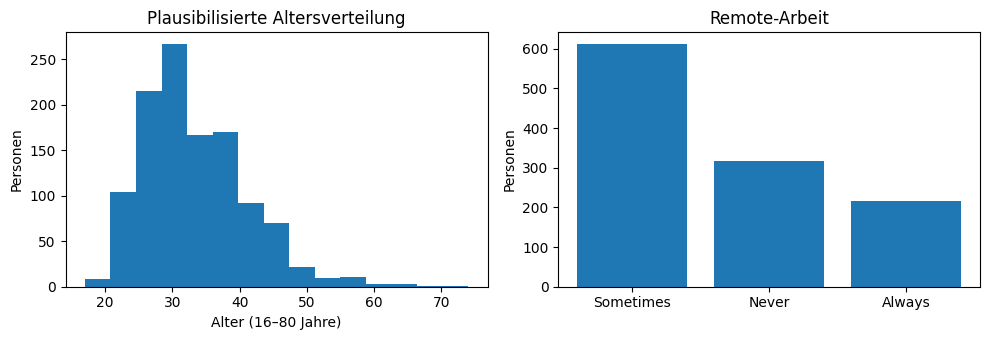

In [ ]:
agecol='What is your age?'; gendercol='What is your gender?'; rolecol='Which of the following best describes your work position?'
age=pd.to_numeric(df[agecol],errors='coerce');age_clean=age.where(age.between(16,80))
print('Unplausible Altersangaben:',int((age.notna()&age_clean.isna()).sum()))
print('Bereinigtes Alter: Median',age_clean.median(),', gültige Werte',int(age_clean.notna().sum()))

raw_gender=df[gendercol].fillna('').astype(str).str.strip().str.casefold()
known_f={'female','f','woman','cis female','cis woman','female (cis)','female/woman'}
known_m={'male','m','man','cis male','cis man','male (cis)','male/man'}
known_nb={'non-binary','nonbinary','non binary','genderqueer','gender fluid','genderfluid'}
def gender_group(s):
    if not s:return 'Keine Angabe'
    if s in known_f:return 'Weiblich (eindeutige Selbstangabe)'
    if s in known_m:return 'Männlich (eindeutige Selbstangabe)'
    if s in known_nb:return 'Nichtbinär (eindeutige Selbstangabe)'
    return 'Sonstige/individuelle/unklare Angabe'
gender_groups=raw_gender.map(gender_group)
print('Geschlecht: verschiedene Rohtexte',df[gendercol].nunique(dropna=True))
print('Konservative deskriptive Kategorien (aggregiert):');print(gender_groups.value_counts().to_string())
role_lists=df[rolecol].fillna('').astype(str).map(lambda s:sorted(set(t.strip() for t in s.split('|') if t.strip())))
role_tokens=sorted({t for tokens in role_lists for t in tokens})
role_multi=pd.DataFrame({t:role_lists.map(lambda a:int(t in a)) for t in role_tokens})
print('Rollen: Rohkombinationen',df[rolecol].nunique(dropna=True),
      '| reihenfolgeunabhängige Kombinationen',role_lists.map(lambda x:'|'.join(x)).nunique(),
      '| Multi-Hot-Indikatoren',len(role_tokens))
role_multi.sum().rename('Anzahl').to_csv(OUT/'rollen_multi_hot_aggregiert.csv')
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
ax[0].hist(age_clean.dropna(),bins=15);ax[0].set(xlabel='Alter (16–80 Jahre)',ylabel='Personen',title='Plausibilisierte Altersverteilung')
rem=df['Do you work remotely?'].value_counts();ax[1].bar(rem.index.astype(str),rem.values);ax[1].set(title='Remote-Arbeit',ylabel='Personen')
fig.tight_layout();fig.savefig(OUT/'02_eda_verteilungen.png',dpi=160);plt.show()

## 3. Merkmalsauswahl und kategoriale Zusammenhänge

Sechs inhaltlich begründete, unmittelbar auf betriebliche Unterstützungsbedingungen bezogene Fragen bilden die Grundlage der Basissegmentierung. „I don't know“ ist eine inhaltlich relevante Antwortkategorie, kein fehlender Wert. Nominale Kategorien werden per One-Hot-Encoding kodiert. Die alternative Analyse ohne „Informationsangebote“ wird **gleichrangig** verglichen. Die Rolle der Freistellung bleibt für K-Means nominal; eine ordinale Abbildung wird nur ergänzend beschrieben. Kategoriale Redundanz wird mit bias-korrigiertem Cramér's V analysiert. Weder die Indizes noch die Multi-Hot-Rollen werden gleichzeitig mit ihren Ursprungsfragen trainiert (sonst Doppelgewichtung).

6 Merkmale: (1146, 22) | Alternative mit 5 Merkmalen: (1146, 19)
Freistellung: fehlender ordinaler Wert bei explizitem Unwissen: 150


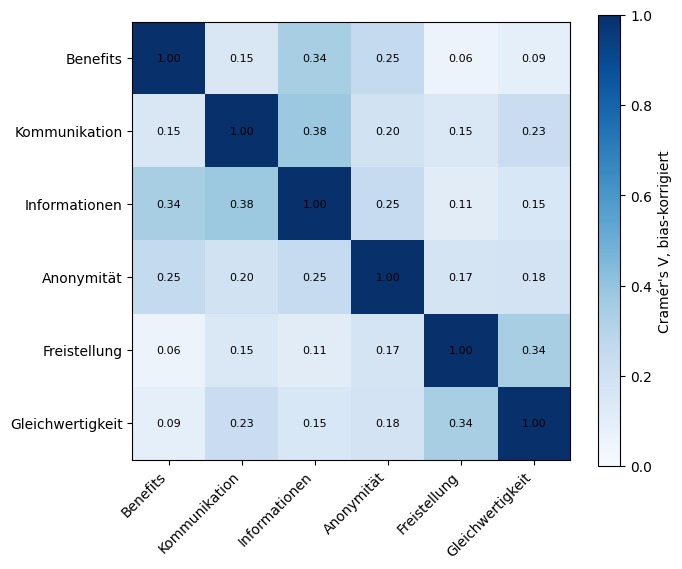

In [ ]:
FEATURES={
 'Benefits':'Does your employer provide mental health benefits as part of healthcare coverage?',
 'Kommunikation':'Has your employer ever formally discussed mental health (for example, as part of a wellness campaign or other official communication)?',
 'Informationen':'Does your employer offer resources to learn more about mental health concerns and options for seeking help?',
 'Anonymität':'Is your anonymity protected if you choose to take advantage of mental health or substance abuse treatment resources provided by your employer?',
 'Freistellung':'If a mental health issue prompted you to request a medical leave from work, asking for that leave would be:',
 'Gleichwertigkeit':'Do you feel that your employer takes mental health as seriously as physical health?'
}
PROFILE={
 'Gesprächsbereitschaft':'Would you feel comfortable discussing a mental health disorder with your direct supervisor(s)?',
 'Negative Folgen':'Do you think that discussing a mental health disorder with your employer would have negative consequences?',
 'Karrierenachteil':'Do you feel that being identified as a person with a mental health issue would hurt your career?'
}
X_cat=df[list(FEATURES.values())].copy();X_cat.columns=list(FEATURES)
assert X_cat.notna().all().all()
enc=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
X=enc.fit_transform(X_cat)
X_cat5=X_cat.drop(columns='Informationen')
X5=OneHotEncoder(sparse_output=False,handle_unknown='ignore').fit_transform(X_cat5)
print('6 Merkmale:',X.shape,'| Alternative mit 5 Merkmalen:',X5.shape)
indices=pd.DataFrame({'Unterstuetzung_Yes':X_cat.drop(columns='Freistellung').eq('Yes').sum(axis=1),
 'Unwissen':X_cat.eq("I don't know").sum(axis=1),
 'Freistellung_ordinal':X_cat['Freistellung'].map({'Very difficult':1,'Somewhat difficult':2,
   'Neither easy nor difficult':3,'Somewhat easy':4,'Very easy':5})})
print('Freistellung: fehlender ordinaler Wert bei explizitem Unwissen:',indices.Freistellung_ordinal.isna().sum())

def cramers_v_bias_corrected(a,b):
    table=pd.crosstab(pd.Series(a).reset_index(drop=True),pd.Series(b).reset_index(drop=True))
    n=table.to_numpy().sum();r,k=table.shape
    if n<=1 or min(r,k)<=1:return np.nan
    chi2=chi2_contingency(table,correction=False)[0]
    phi2_corr=max(0,chi2/n-(k-1)*(r-1)/(n-1))
    r_corr=r-(r-1)**2/(n-1);k_corr=k-(k-1)**2/(n-1)
    return float(np.sqrt(phi2_corr/min(r_corr-1,k_corr-1))) if min(r_corr-1,k_corr-1)>0 else np.nan
corr=pd.DataFrame({a:{b:cramers_v_bias_corrected(X_cat[a],X_cat[b]) for b in X_cat} for a in X_cat})
corr.to_csv(OUT/'cramers_v_merkmale.csv')
fig,ax=plt.subplots(figsize=(7,5.8)); im=ax.imshow(corr,cmap='Blues',vmin=0,vmax=1)
ax.set_xticks(range(6),corr.columns,rotation=45,ha='right');ax.set_yticks(range(6),corr.index)
for i in range(6):
 for j in range(6):ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',fontsize=8)
fig.colorbar(im,ax=ax,label="Cramér's V, bias-korrigiert");fig.tight_layout();fig.savefig(OUT/'03_cramers_v.png',dpi=160);plt.show()

## 4. K-Means-Basismodell versus konkurrierendes Fünf-Merkmals-Modell

Die Basislösung mit drei Gruppen ist **nicht eindeutig optimal**: Ihre Silhouette ist niedrig, und die Informationsfrage besitzt exakt drei Antwortkategorien. Daher prüfen wir zusätzlich das Modell **ohne** diese Variable. Höhere Silhouette bei veränderter Merkmalsanzahl ist kein Beweis, dass eines der Modelle „wahrer“ ist. Der Vergleich dient der Sensitivitätsanalyse und der Frage, ob die Basissegmentierung mehr als eine Kreuztabelle liefert.

In [ ]:
km=KMeans(n_clusters=3,random_state=SEED,n_init=30).fit(X)
y=km.labels_
km5=KMeans(n_clusters=3,random_state=SEED,n_init=30).fit(X5)
y5=km5.labels_
print('6 Merkmale:',np.bincount(y).tolist(),'Silhouette',round(silhouette_score(X,y),5))
print('5 Merkmale:',np.bincount(y5).tolist(),'Silhouette',round(silhouette_score(X5,y5),5))
print('ARI (6 vs. 5):',round(adjusted_rand_score(y,y5),5))
info=X_cat['Informationen']
print('6 Merkmale: Cluster vs. Informationsantwort Cramér V',round(cramers_v_bias_corrected(y,info),4),
      ', ARI',round(adjusted_rand_score(y,info),4))
print('5 Merkmale: Cluster vs. Informationsantwort Cramér V',round(cramers_v_bias_corrected(y5,info),4))
print('Indexmittelwerte für das Basis- und Alternativmodell:')
indexprofile=pd.concat({'Sechs Merkmale':indices.groupby(y).mean(),
                        'Fünf Merkmale':indices.groupby(y5).mean()},names=['Modell','Cluster'])
display(indexprofile.round(2));indexprofile.to_csv(OUT/'indizes_je_cluster.csv')
indexcounts=pd.concat({'Sechs Merkmale':indices.groupby(y).count(),
                       'Fünf Merkmale':indices.groupby(y5).count()},names=['Modell','Cluster'])
print('Fallzahlen pro Index und Cluster (insbesondere ordinale Freistellung):')
display(indexcounts);indexcounts.to_csv(OUT/'index_fallzahlen_je_cluster.csv')

6 Merkmale: [308, 340, 498] Silhouette 0.15485
5 Merkmale: [357, 487, 302] Silhouette 0.17688
ARI (6 vs. 5): 0.06799
6 Merkmale: Cluster vs. Informationsantwort Cramér V 0.8967 , ARI 0.8185
5 Merkmale: Cluster vs. Informationsantwort Cramér V 0.1679
Indexmittelwerte für das Basis- und Alternativmodell:


Unterstuetzung_Yes  Unwissen  Freistellung_ordinal
Modell         Cluster                                                    
Sechs Merkmale 0                      0.87      3.14                  3.21
               1                      3.33      1.02                  3.79
               2                      0.65      1.63                  2.98
Fünf Merkmale  0                      2.76      1.22                  4.08
               1                      0.92      2.66                  3.16
               2                      0.97      1.31                  2.47

Fallzahlen pro Index und Cluster (insbesondere ordinale Freistellung):


Unterstuetzung_Yes  Unwissen  Freistellung_ordinal
Modell         Cluster                                                    
Sechs Merkmale 0                       308       308                   256
               1                       340       340                   303
               2                       498       498                   437
Fünf Merkmale  0                       357       357                   337
               1                       487       487                   395
               2                       302       302                   264

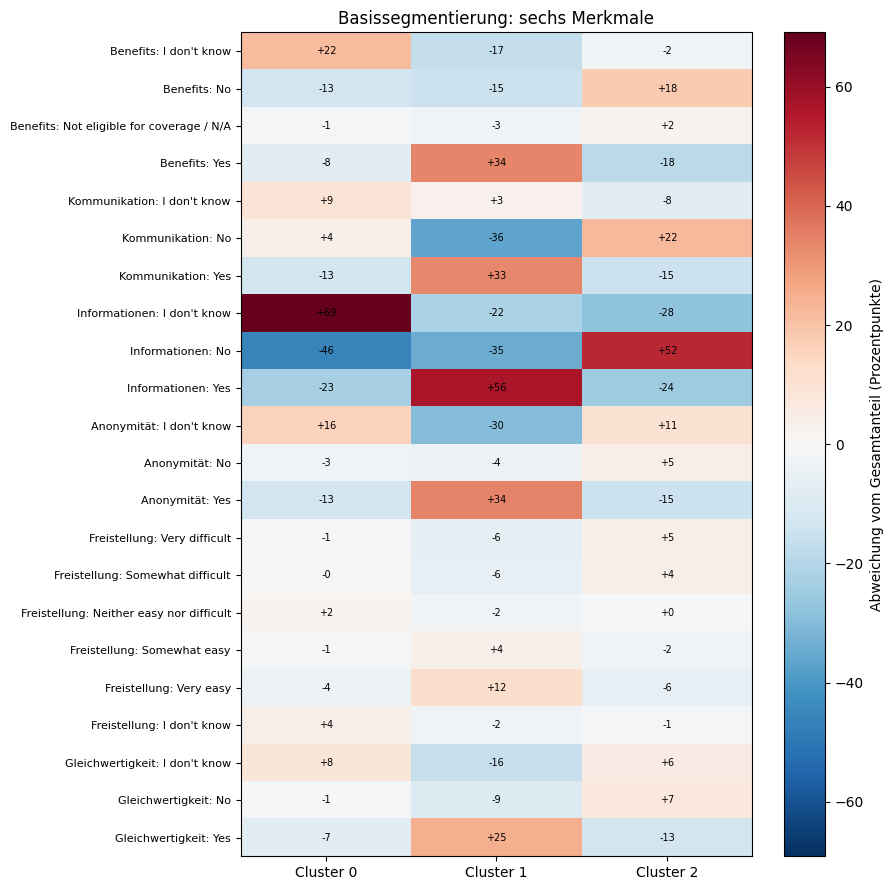

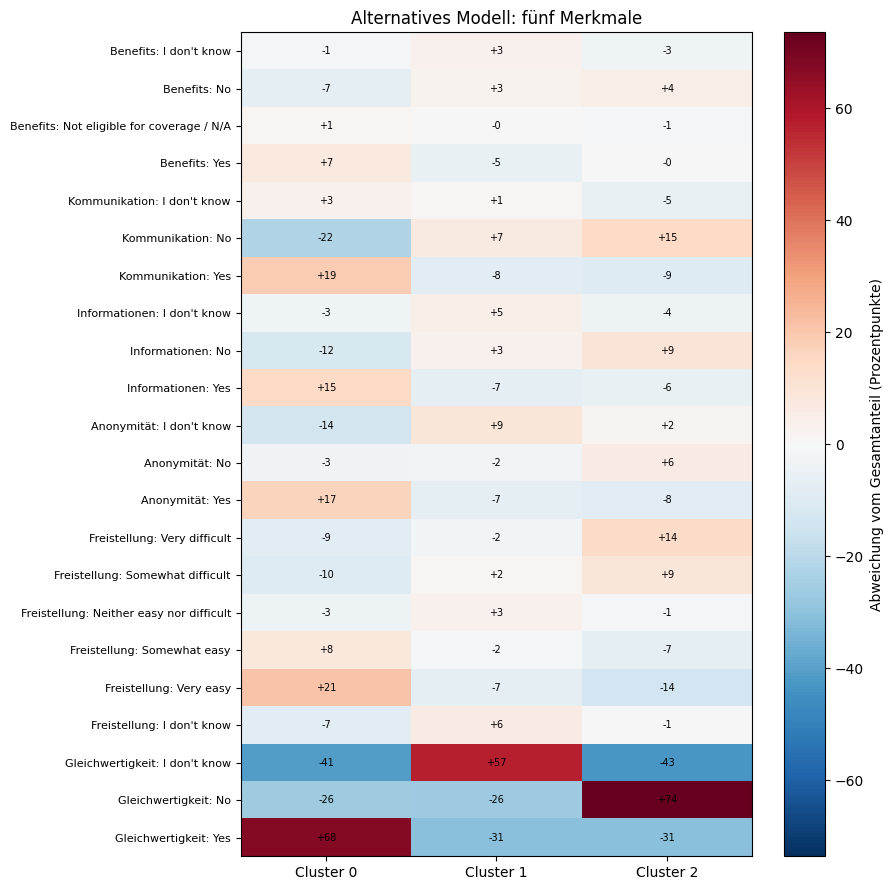

In [ ]:
def profile_table(data,labels):
    rows=[]
    for feature in data.columns:
        all_freq=data[feature].value_counts(normalize=True)
        for answer in all_freq.index:
            for cluster in sorted(np.unique(labels)):
                freq=(data.loc[labels==cluster,feature]==answer).mean()*100
                rows.append(dict(Merkmal=feature,Antwort=str(answer),Cluster=int(cluster),
                                 Cluster_Prozent=round(freq,2),Gesamt_Prozent=round(all_freq[answer]*100,2),
                                 Abweichung_pp=round(freq-all_freq[answer]*100,2)))
    return pd.DataFrame(rows)
answer_order={'Freistellung':['Very difficult','Somewhat difficult','Neither easy nor difficult','Somewhat easy','Very easy',"I don't know"]}
def profile_heatmap(profile,name,file):
    tab=profile.pivot(index=['Merkmal','Antwort'],columns='Cluster',values='Abweichung_pp')
    seq=[]
    for feature in FEATURES:
        for a in answer_order.get(feature,[]):
            if (feature,a) in tab.index:seq.append((feature,a))
        seq.extend([(feature,a) for f,a in tab.index if f==feature and (f,a) not in seq])
    tab=tab.loc[seq]
    lim=max(20,float(np.max(np.abs(tab.to_numpy()))))
    fig,ax=plt.subplots(figsize=(9,9));im=ax.imshow(tab,cmap='RdBu_r',vmin=-lim,vmax=lim,aspect='auto')
    ax.set_xticks(range(3),['Cluster 0','Cluster 1','Cluster 2'])
    ax.set_yticks(range(len(tab)),[f'{a}: {b}' for a,b in tab.index],fontsize=8)
    for i in range(len(tab)):
      for j in range(3):ax.text(j,i,f'{tab.iloc[i,j]:+.0f}',ha='center',va='center',fontsize=7)
    ax.set_title(name);fig.colorbar(im,ax=ax,label='Abweichung vom Gesamtanteil (Prozentpunkte)')
    fig.tight_layout();fig.savefig(OUT/file,dpi=175);plt.show()
base=profile_table(X_cat,y);alt=profile_table(X_cat,y5)
base.to_csv(OUT/'clusterprofil_6_merkmale.csv',index=False)
alt.to_csv(OUT/'clusterprofil_5_merkmale.csv',index=False)
profile_heatmap(base,'Basissegmentierung: sechs Merkmale','04a_heatmap_basis.png')
profile_heatmap(alt,'Alternatives Modell: fünf Merkmale','04b_heatmap_ohne_informationen.png')

## 5. Clusterzahl und Methodenvergleich (k = 2 bis 8)

K-Means optimiert quadrierte euklidische Abstände auf One-Hot-Features; k-Modes minimiert kategoriale Fehlübereinstimmungen. **Bei derselben One-Hot-Kodierung** entspricht der quadrierte euklidische Abstand zweier Fälle dem Zweifachen der Anzahl abweichender Originalfragen. Ein Vergleich der Silhouette auf einer gemeinsamen Hamming-Distanz ist deshalb sinnvoll, allerdings sind die Verfahren hinsichtlich ihres Optimierungsziels und ihrer Initialisierung nicht identisch. k-Modes wird mit der etablierten Bibliothek sowie Huang- und Cao-Initialisierung ausgeführt; die Kosten dürfen nur **innerhalb der k-Modes-Zielfunktion** verglichen werden.

k-Modes-Kosten der K-Means-Partition: 2606


,Verfahren,k,Silhouette_Hamming,Silhouette_euklidisch,Calinski_Harabasz,Davies_Bouldin,Zielwert,Kleinste_Gruppe
0,K-Means,2,0.263,0.154,192.637,2.327,3656.236,409
1,k-Modes Huang,2,0.260,NaN,NaN,NaN,2878.000,306
2,K-Means,3,0.264,0.155,175.520,2.163,3268.178,308
3,k-Modes Huang,3,0.184,NaN,NaN,NaN,2492.000,268
4,K-Means,4,0.226,0.136,150.431,2.228,3061.908,261
5,k-Modes Huang,4,0.176,NaN,NaN,NaN,2331.000,203
6,K-Means,5,0.233,0.141,138.077,2.066,2878.533,177
7,k-Modes Huang,5,0.169,NaN,NaN,NaN,2153.000,160
8,K-Means,6,0.231,0.141,126.509,2.012,2747.446,163
9,k-Modes Huang,6,0.139,NaN,NaN,NaN,2161.000,69


Huang k=3: Kosten 2492.0 Gruppengrößen [568 268 310] ARI zur K-Means-Basissegmentierung 0.386
Cao k=3: Kosten 2823.0 Gruppengrößen [747 224 175] ARI zu Huang 0.101


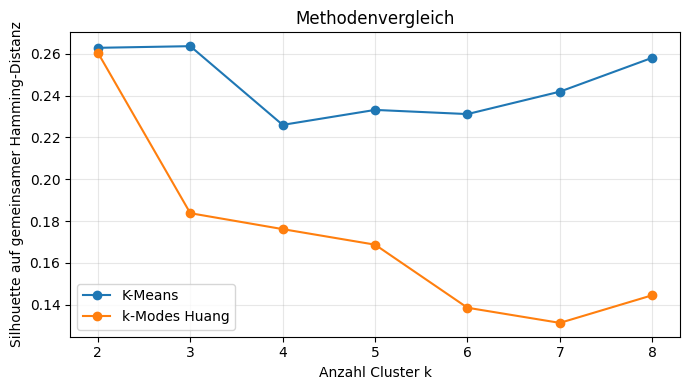

In [ ]:
cat_values=X_cat.astype(str).to_numpy()
X_codes=np.column_stack([X_cat[col].astype('category').cat.codes for col in X_cat])
D=pairwise_distances(X_codes,metric='hamming')
def kmodes_cost_of_partition(A,labels):
    total=0
    for cluster in np.unique(labels):
        subset=A[np.asarray(labels)==cluster]
        for j in range(A.shape[1]):
            total+=len(subset)-pd.Series(subset[:,j]).value_counts().iloc[0]
    return int(total)
print('k-Modes-Kosten der K-Means-Partition:',kmodes_cost_of_partition(cat_values,y))
rows=[];ref_mode=None
for k in range(2,9):
    fitted=KMeans(n_clusters=k,n_init=30,random_state=SEED).fit(X)
    ky=fitted.labels_
    rows.append({'Verfahren':'K-Means','k':k,
      'Silhouette_Hamming':silhouette_score(D,ky,metric='precomputed'),
      'Silhouette_euklidisch':silhouette_score(X,ky),
      'Calinski_Harabasz':calinski_harabasz_score(X,ky),
      'Davies_Bouldin':davies_bouldin_score(X,ky),
      'Zielwert':fitted.inertia_,'Kleinste_Gruppe':int(np.bincount(ky).min())})
    fitted_modes=KModes(n_clusters=k,init='Huang',n_init=10,random_state=SEED,verbose=0).fit(cat_values)
    my=fitted_modes.labels_
    rows.append({'Verfahren':'k-Modes Huang','k':k,
      'Silhouette_Hamming':silhouette_score(D,my,metric='precomputed'),
      'Silhouette_euklidisch':np.nan,'Calinski_Harabasz':np.nan,'Davies_Bouldin':np.nan,
      'Zielwert':fitted_modes.cost_,'Kleinste_Gruppe':int(np.bincount(my).min())})
    if k==3:ref_mode=my.copy();fit_mode=fitted_modes
model_comp=pd.DataFrame(rows)
model_comp.to_csv(OUT/'methodenvergleich_k2_bis8.csv',index=False)
display(model_comp.round(3))
print('Huang k=3: Kosten',fit_mode.cost_,'Gruppengrößen',np.bincount(ref_mode),
      'ARI zur K-Means-Basissegmentierung',round(adjusted_rand_score(y,ref_mode),3))
cao=KModes(n_clusters=3,init='Cao',n_init=1,random_state=SEED,verbose=0).fit(cat_values)
print('Cao k=3: Kosten',cao.cost_,'Gruppengrößen',np.bincount(cao.labels_),
      'ARI zu Huang',round(adjusted_rand_score(cao.labels_,ref_mode),3))
fig,ax=plt.subplots(figsize=(7,4))
for name,g in model_comp.groupby('Verfahren'):
 ax.plot(g.k,g.Silhouette_Hamming,marker='o',label=name)
ax.set(xlabel='Anzahl Cluster k',ylabel='Silhouette auf gemeinsamer Hamming-Distanz',title='Methodenvergleich')
ax.grid(alpha=.3);ax.legend();fig.tight_layout();fig.savefig(OUT/'05_methodenvergleich.png',dpi=160);plt.show()

## 6. Stabilität und Merkmalssensitivität

Die Reproduzierbarkeit über verschiedene Startwerte ist nicht mit struktureller Stabilität gleichzusetzen. Deshalb werden zufällige **80-%-Teilstichproben ohne Zurücklegen** gezogen, Modelle neu trainiert und die Clusterzuordnungen auf denselben vollständigen Fällen per ARI verglichen. Ein hoher Wert bei fixen Features widerlegt nicht die Sensitivität gegenüber der Weglassung einzelner Fragen. k-Modes verwendet überall die **Bibliotheksimplementierung**.

In [ ]:
seeds=[3,17,27,42,93]
seed_y=[KMeans(n_clusters=3,n_init=20,random_state=s).fit_predict(X) for s in seeds]
print('K-Means-Initialisierungsstabilität (ARI zu Referenz):',np.round([adjusted_rand_score(y,yy) for yy in seed_y],3))
loo=[]
for feat in FEATURES:
    x_sub=OneHotEncoder(sparse_output=False).fit_transform(X_cat.drop(columns=feat))
    yy=KMeans(n_clusters=3,n_init=30,random_state=SEED).fit_predict(x_sub)
    loo.append({'Weggelassen':feat,'ARI_zur_Basis':adjusted_rand_score(y,yy),
                'Silhouette_euklidisch':silhouette_score(x_sub,yy)})
loo=pd.DataFrame(loo);loo.to_csv(OUT/'leave_one_feature_out.csv',index=False)
display(loo.round(3))
rng=np.random.default_rng(2026)
subs=[]
for rep in range(12):
    ids=rng.choice(len(X),size=int(.8*len(X)),replace=False)
    yp=KMeans(n_clusters=3,n_init=15,random_state=100+rep).fit(X[ids]).predict(X)
    md=KModes(n_clusters=3,init='Huang',n_init=10,random_state=100+rep,verbose=0).fit(cat_values[ids])
    mp=md.predict(cat_values)
    subs.extend([{'Verfahren':'K-Means','Lauf':rep+1,'ARI':adjusted_rand_score(y,yp)},
                 {'Verfahren':'k-Modes Huang','Lauf':rep+1,'ARI':adjusted_rand_score(ref_mode,mp)}])
stab=pd.DataFrame(subs);stab.to_csv(OUT/'subsampling_12_laeufe.csv',index=False)
display(stab.groupby('Verfahren').ARI.agg(['median','mean','min','max']).round(3))

K-Means-Initialisierungsstabilität (ARI zu Referenz): [1.    1.    1.    1.    0.998]


,Weggelassen,ARI_zur_Basis,Silhouette_euklidisch
0,Benefits,0.795,0.182
1,Kommunikation,0.757,0.161
2,Informationen,0.068,0.177
3,Anonymität,0.855,0.180
4,Freistellung,0.912,0.217
5,Gleichwertigkeit,0.879,0.194


,median,mean,min,max
Verfahren,,,,
K-Means,0.989,0.976,0.908,0.996
k-Modes Huang,0.381,0.471,0.242,0.825


## 7. Dimensionsreduktion und Visualisierungsgrenzen

PCA ist die lineare Referenz auf den One-Hot-Daten. MCA ist für kategoriale Merkmale geeigneter; sie wird als Korrespondenzanalyse der vollständigen disjunktiven Indikatormatrix berechnet. Die zwei Dimensionen zeigen nur einen Teil der Streuung bzw. Inertie, und Jitter dient ausschließlich der Sichtbarkeit überlagerter Beobachtungen. Ein möglicher Bogen-/Hufeiseneffekt in der MCA ist keine eigenständige Validierung von Clustern. Kategoriepunkte werden zur inhaltlichen Orientierung zusätzlich eingezeichnet.

PCA: Anteil der ersten 2 Komponenten: 31.63 %


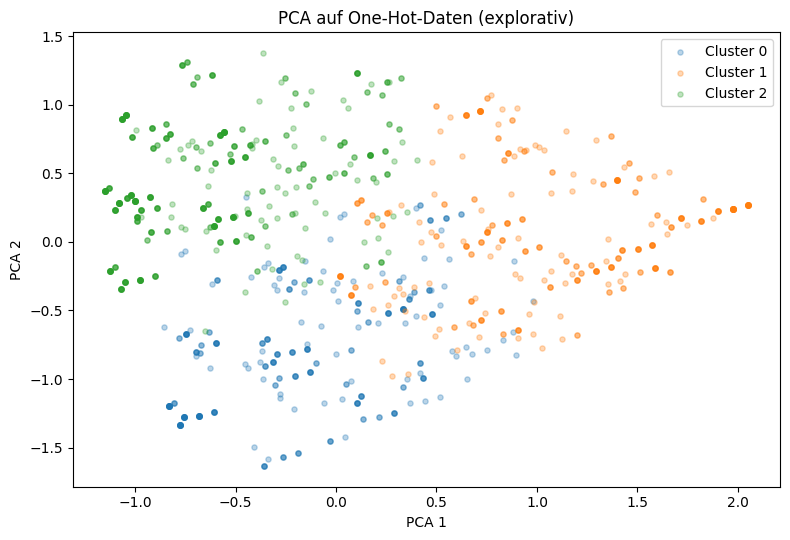

MCA 2D: Anteil an UNBEREINIGTER Inertie: 24.72 %


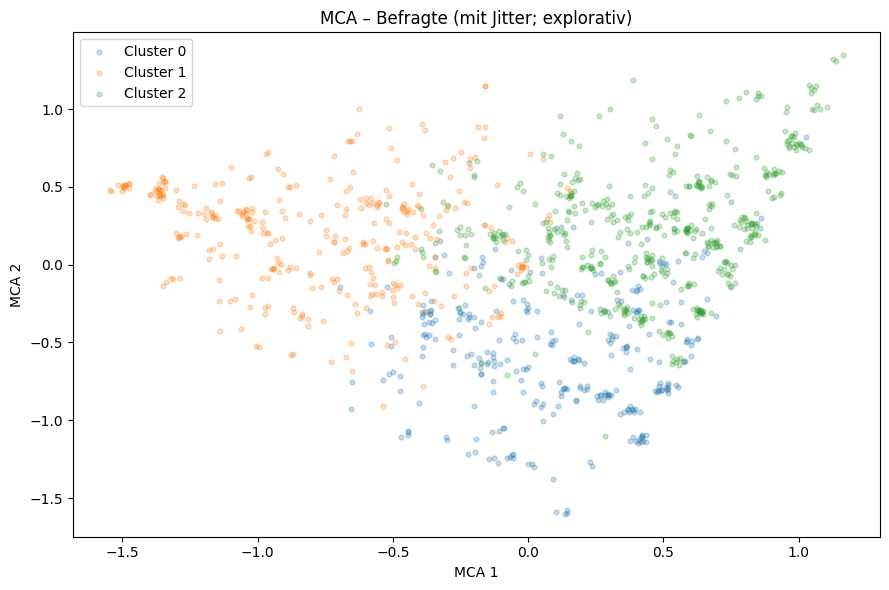

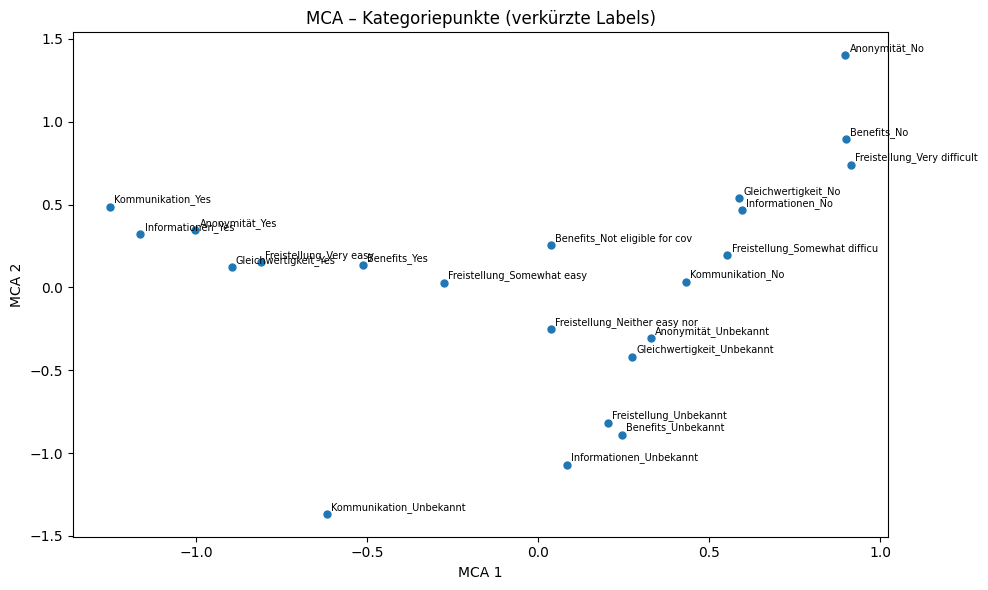

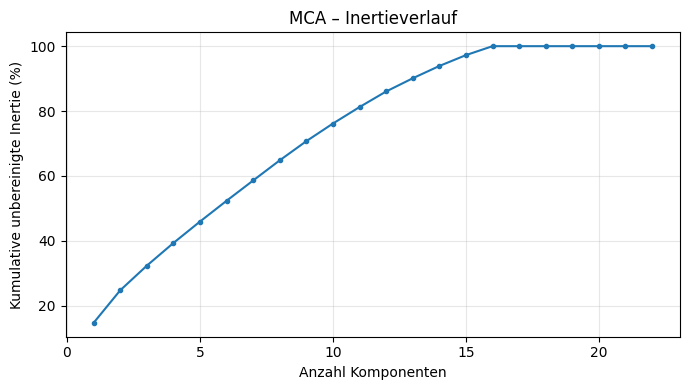

In [ ]:
pca=PCA(n_components=2,random_state=SEED).fit(X)
P=pca.transform(X)
print('PCA: Anteil der ersten 2 Komponenten:',round(100*pca.explained_variance_ratio_.sum(),2),'%')
fig,ax=plt.subplots(figsize=(8,5.5))
for cl in np.unique(y):
 idx=np.where(y==cl)[0];ax.scatter(P[idx,0],P[idx,1],s=14,alpha=.3,label=f'Cluster {cl}')
ax.set(xlabel='PCA 1',ylabel='PCA 2',title='PCA auf One-Hot-Daten (explorativ)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'06a_pca.png',dpi=160);plt.show()

Z=X.astype(float);Pmat=Z/Z.sum();r=Pmat.sum(axis=1);c=Pmat.sum(axis=0)
S=(Pmat-np.outer(r,c))/np.sqrt(np.outer(r,c))
U,s,Vt=np.linalg.svd(S,full_matrices=False)
inertia=s*s
row_scores=(U[:,:2]*s[:2])/np.sqrt(r[:,None])
col_scores=(Vt.T[:,:2]*s[:2])/np.sqrt(c[:,None])
print('MCA 2D: Anteil an UNBEREINIGTER Inertie:',round(100*inertia[:2].sum()/inertia.sum(),2),'%')
fig,ax=plt.subplots(figsize=(9,6));noise=np.random.default_rng(SEED)
for cl in np.unique(y):
 idx=np.where(y==cl)[0]
 pts=row_scores[idx]+noise.normal(0,.018,(len(idx),2))
 ax.scatter(pts[:,0],pts[:,1],s=12,alpha=.25,label=f'Cluster {cl}')
# Eigenes separates Kategorie-Biplot statt unlesbarer 22 Labels im Personenplot
ax.set(xlabel='MCA 1',ylabel='MCA 2',title='MCA – Befragte (mit Jitter; explorativ)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'06b_mca_personen.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(10,6))
ax.scatter(col_scores[:,0],col_scores[:,1],s=25)
for i,feature in enumerate(enc.get_feature_names_out()):
 ax.annotate(feature.replace("I don't know",'Unbekannt')[:29],(col_scores[i,0],col_scores[i,1]),fontsize=7,xytext=(3,3),textcoords='offset points')
ax.set(xlabel='MCA 1',ylabel='MCA 2',title='MCA – Kategoriepunkte (verkürzte Labels)');fig.tight_layout()
fig.savefig(OUT/'06c_mca_kategorien.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(7,4))
ax.plot(np.arange(1,len(inertia)+1),np.cumsum(inertia)/inertia.sum()*100,marker='o',ms=3)
ax.set(xlabel='Anzahl Komponenten',ylabel='Kumulative unbereinigte Inertie (%)',title='MCA – Inertieverlauf')
ax.grid(alpha=.3);fig.tight_layout();fig.savefig(OUT/'06d_mca_inertie.png',dpi=160);plt.show()

## 8. Externe Profile und Unternehmenskontext

Zur ergänzenden Charakterisierung der Cluster werden drei thematisch verwandte HR-Fragen sowie die Unternehmensgröße, der Organisationstyp und das Arbeitsland untersucht. Diese Merkmale wurden nicht für die Clusterbildung verwendet. Da die HR-Fragen den Trainingsmerkmalen inhaltlich nahestehen, stellen sie jedoch keine vollständig unabhängige Validierung dar.

Die Zusammenhänge werden anhand aggregierter Antwortverteilungen und Cramér's V beschrieben. Dabei zeigen sich überwiegend kleine bis mäßige Effektstärken. Der stärkste Zusammenhang unter den untersuchten externen Merkmalen besteht mit der Unternehmensgröße (V ≈ 0,24). Zur Veranschaulichung werden die Clusteranteile innerhalb der einzelnen Größenklassen dargestellt.

Für das Arbeitsland werden aufgrund zahlreicher seltener Einzelkategorien zusätzlich die Gruppen USA, Vereinigtes Königreich und übrige Länder gebildet. Eine inferenzstatistische Auswertung erfolgt nur bei ausreichenden erwarteten Zellhäufigkeiten.

Die beobachteten Zusammenhänge erlauben keine kausalen Schlussfolgerungen. Zudem könnten mehrere Befragte demselben Arbeitgeber angehören, sodass die Beobachtungen möglicherweise nicht unabhängig sind. Die Ergebnisse lassen deshalb keine eindeutigen Rückschlüsse auf Unterschiede zwischen einzelnen Unternehmen zu. Bei der Interpretation werden Effektstärken und inhaltliche Relevanz stärker gewichtet als die statistische Signifikanz allein.

,Gruppe,Merkmal,Cramers_V_bias_korrigiert,Min_erwartete_Zellzahl
0,HR,Gesprächsbereitschaft,0.185,90.304
1,HR,Negative Folgen,0.138,59.396
2,HR,Karrierenachteil,0.121,6.719
3,Kontext,Organisationstyp,0.102,70.684
4,Kontext,Unternehmensgröße,0.241,16.126
5,Kontext,Arbeitsland,0.144,0.269


Kontext- und HR-Vergleiche mit Effektstärken:


,Gruppe,Merkmal,Chi2,df,p_formatiert,Cramers_V_bias_korrigiert,Min_erwartete_Zellzahl,Interpretation
0,HR,Gesprächsbereitschaft,81.942,4.0,"p < 0,001",0.185,90.304,χ²-Test berichtet (alle erwarteten Zellen >= 5)
1,HR,Negative Folgen,47.686,4.0,"p < 0,001",0.138,59.396,χ²-Test berichtet (alle erwarteten Zellen >= 5)
2,HR,Karrierenachteil,41.729,8.0,"p < 0,001",0.121,6.719,χ²-Test berichtet (alle erwarteten Zellen >= 5)
3,Kontext,Organisationstyp,13.897,2.0,"p < 0,001",0.102,70.684,χ²-Test berichtet (alle erwarteten Zellen >= 5)
4,Kontext,Unternehmensgröße,143.263,10.0,"p < 0,001",0.241,16.126,χ²-Test berichtet (alle erwarteten Zellen >= 5)
5,Kontext,Arbeitsland,NaN,NaN,nicht berechnet,0.144,0.269,χ²/p nicht berichtet (erwartete Zellen < 5); V...


Arbeitsland (USA / UK / andere) – minimale erwartete Zellzahl: 35.75
χ²-Test der drei Ländergruppen: p < 0,001 | Cramér V: 0.158


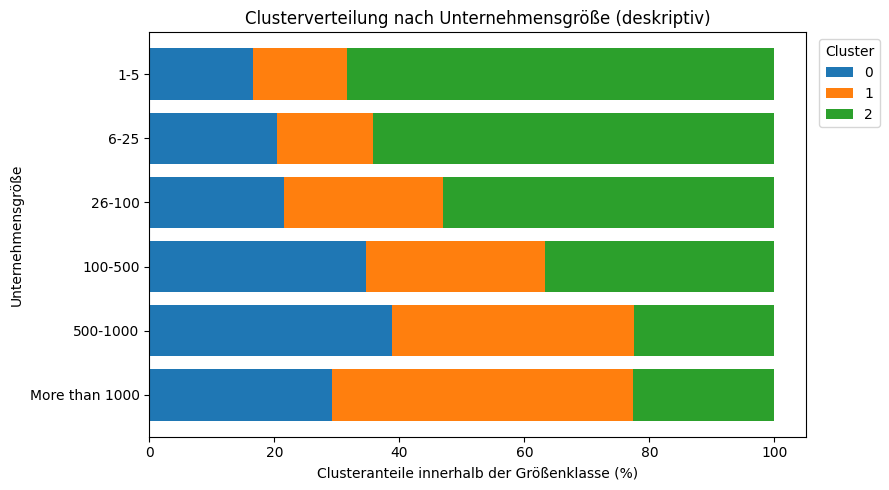

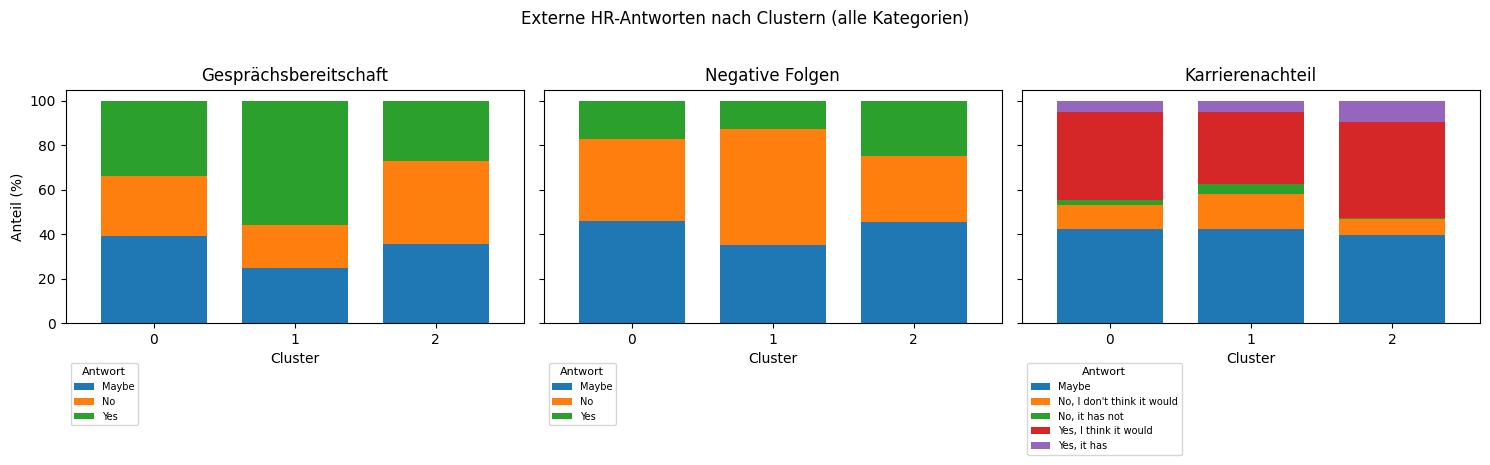

In [ ]:
EXTERNAL={'Organisationstyp':'Is your employer primarily a tech company/organization?',
          'Unternehmensgröße':'How many employees does your company or organization have?',
          'Arbeitsland':'What country do you work in?'}
rows=[]
for group,vars_ in [('HR',PROFILE),('Kontext',EXTERNAL)]:
 for name,col in vars_.items():
    tab=pd.crosstab(pd.Series(y,name='Cluster'),df[col])
    if tab.shape[1]<2:continue
    chi2,p,dof,expected=chi2_contingency(tab)
    v=cramers_v_bias_corrected(pd.Series(y),df[col])
    test_zulaessig=bool((expected>=5).all())
    rows.append({'Gruppe':group,'Merkmal':name,
                 'Chi2':chi2 if test_zulaessig else np.nan,
                 'df':dof if test_zulaessig else np.nan,
                 'p_Wert':p if test_zulaessig else np.nan,
                 'Cramers_V_bias_korrigiert':v,
                 'Min_erwartete_Zellzahl':float(expected.min()),
                 'Interpretation':('χ²-Test berichtet (alle erwarteten Zellen >= 5)'
                    if test_zulaessig else 'χ²/p nicht berichtet (erwartete Zellen < 5); V nur explorativ')})
    tab.div(tab.sum(axis=1),axis=0).mul(100).round(2).to_csv(OUT/f'externe_anteile_{name.replace(" ","_")}.csv')
results=pd.DataFrame(rows);results.to_csv(OUT/'externe_tests.csv',index=False)
display(results[['Gruppe','Merkmal','Cramers_V_bias_korrigiert','Min_erwartete_Zellzahl']].round(3))
def p_format(p):
    if pd.isna(p):return 'nicht berechnet'
    return 'p < 0,001' if p<.001 else f'p = {p:.3f}'.replace('.',',')
results['p_formatiert']=results.p_Wert.map(p_format)
print('Kontext- und HR-Vergleiche mit Effektstärken:')
display(results[['Gruppe','Merkmal','Chi2','df','p_formatiert',
                 'Cramers_V_bias_korrigiert','Min_erwartete_Zellzahl','Interpretation']].round(3))
# Bei Kleinstkategorien keine globalen Länder-Tests behaupten.
land=df[EXTERNAL['Arbeitsland']].fillna('Keine Angabe').astype(str).str.strip()
land_group=land.map(lambda x:'USA' if x in ('United States of America','United States')
                    else ('UK' if x in ('United Kingdom','UK') else 'Andere Länder'))
land_ct=pd.crosstab(pd.Series(y,name='Cluster'),land_group)
chi_land,p_land,dof_land,exp_land=chi2_contingency(land_ct)
land_test_zulaessig=bool((exp_land>=5).all())
print('Arbeitsland (USA / UK / andere) – minimale erwartete Zellzahl:',round(float(exp_land.min()),2))
if land_test_zulaessig:
    print('χ²-Test der drei Ländergruppen:',p_format(p_land),
          '| Cramér V:',round(cramers_v_bias_corrected(y,land_group),3))
else:
    print('Kein χ²-Test / p-Wert für Ländergruppen berichtet: erwartete Zellzahl < 5.')
    print('Cramér V nur deskriptiv/explorativ:',round(cramers_v_bias_corrected(y,land_group),3))
land_ct.div(land_ct.sum(axis=1),axis=0).mul(100).round(2).to_csv(OUT/'arbeitsland_3_gruppen_prozent.csv')
# Unternehmensgröße: ausdrücklich als Clusterverteilung innerhalb der Größenklassen.
size=df[EXTERNAL['Unternehmensgröße']].fillna('Keine Angabe')
size_tab=pd.crosstab(size,pd.Series(y,name='Cluster'),normalize='index').mul(100)
# Fachliche Größenreihenfolge statt alphabetischer Sortierung
size_order=['1-5','6-25','26-100','100-500','500-1000','More than 1000']
weitere_groessen=[label for label in size_tab.index if label not in size_order]
size_tab=size_tab.reindex([label for label in size_order if label in size_tab.index]+weitere_groessen)
size_tab.to_csv(OUT/'clusteranteile_je_unternehmensgroesse.csv')
fig,ax=plt.subplots(figsize=(9,5))
size_tab.iloc[::-1].plot(kind='barh',stacked=True,ax=ax,width=.8)
ax.set(xlabel='Clusteranteile innerhalb der Größenklasse (%)',ylabel='Unternehmensgröße',
       title='Clusterverteilung nach Unternehmensgröße (deskriptiv)')
ax.legend(title='Cluster',bbox_to_anchor=(1.01,1),loc='upper left')
fig.tight_layout();fig.savefig(OUT/'08_unternehmensgroesse_cluster.png',dpi=170);plt.show()
# Vollständige kategoriale HR-Profile – alle Antwortklassen, nicht nur Ja.
fig,axs=plt.subplots(1,len(PROFILE),figsize=(15,4.7),sharey=True)
for ax,(name,col) in zip(axs,PROFILE.items()):
    pp=pd.crosstab(pd.Series(y,name='Cluster'),df[col],normalize='index').mul(100)
    pp.plot(kind='bar',stacked=True,ax=ax,legend=True,width=.75)
    ax.set(title=name,xlabel='Cluster',ylabel='Anteil (%)');ax.tick_params(axis='x',rotation=0)
    ax.legend(title='Antwort',fontsize=7,title_fontsize=8,loc='upper left',bbox_to_anchor=(0,-.15))
fig.suptitle('Externe HR-Antworten nach Clustern (alle Kategorien)',y=1.02)
fig.tight_layout();fig.savefig(OUT/'09_externe_hr_alle_kategorien.png',dpi=170,bbox_inches='tight');plt.show()


## 9. Wissenschaftliche Schlussfolgerung und endgültige Modellentscheidung

**Modellentscheidung:** Das Sechs-Merkmals-Modell mit K-Means und drei Clustern wird als exploratives, für das HR-Szenario handlungsnahes Hauptmodell verwendet. Die Fünf-Merkmals-Lösung wird als inhaltlich relevante Alternative gleichrangig diskutiert. Die Entscheidung beruht auf der Interpretierbarkeit und dem Anwendungsbezug, nicht auf einem eindeutig nachgewiesenen statistischen Optimum.

**1. Clusterbildung und Merkmalsdominanz**

Die Dreiersegmentierung wird stark durch die Frage nach betrieblichen Informationsangeboten geprägt (Cramér's V ≈ 0,90; ARI ≈ 0,82). Die gewählte Clusterzahl entspricht zudem den drei Antwortkategorien dieser Frage. Ein zusätzlicher Erkenntnisgewinn gegenüber einer einfachen Kreuztabelle entsteht durch die gemeinsame Betrachtung weiterer Unterstützungs- und Kommunikationsmerkmale. Die geringe Silhouette des Hauptmodells (0,155) zeigt allerdings, dass keine deutlich getrennten natürlichen Beschäftigtentypen identifiziert wurden.

**2. Alternative Merkmalsauswahl**

Nach Ausschluss der Informationsfrage entsteht eine grundlegend andere Segmentierung (ARI ≈ 0,068). Das Fünf-Merkmals-Modell unterscheidet insbesondere die wahrgenommene Möglichkeit einer gesundheitsbedingten Freistellung stärker, während die Unterschiede bei den Unterstützungs- und Unwissensindizes geringer ausfallen. Die ordinale Freistellungsvariable berücksichtigt ausschließlich Antworten mit bekanntem Wert; ihre Interpretation erfordert daher die jeweiligen gültigen Fallzahlen. Die höhere Silhouette des Alternativmodells (0,177) belegt aufgrund des veränderten Merkmalsraums keine allgemeine Überlegenheit.

**3. Methodenvergleich und Stabilität**

K-Means weist bei wiederholten Teilstichproben eine höhere Zuordnungsstabilität auf (medianer ARI ≈ 0,99) als die getestete k-Modes-Lösung (medianer ARI ≈ 0,38). Dagegen erzielt k-Modes mit Huang-Initialisierung geringere kategoriale Abweichungskosten (2.492 gegenüber 2.606 für die K-Means-Partition). Die abweichenden Ergebnisse der Huang- und Cao-Initialisierung verdeutlichen zusätzlich die Sensitivität gegenüber der Initialisierung. Da beide Verfahren unterschiedliche Zielfunktionen optimieren, lässt sich aus diesen Kennzahlen keine eindeutige methodische Überlegenheit ableiten.

**4. Dimensionsreduktion**

Die MCA unterstützt die explorative Interpretation der kategorialen Antworten. Ihre erste Dimension lässt sich anhand der Kategoriepunkte vorsichtig als wahrgenommenes Angebotsniveau und die zweite als Informationsunsicherheit interpretieren. Ein möglicher Hufeiseneffekt schränkt diese Deutung ein. Die ersten beiden Dimensionen erfassen lediglich einen Teil der unbereinigten Inertie. Die Ergebnisse sind deshalb als zweidimensionale Projektion und nicht als vollständige Repräsentation der Daten zu verstehen.

**5. Unternehmenskontext und Übertragbarkeit**

Unter den ausgewählten externen Merkmalen zeigt die Unternehmensgröße den stärksten Zusammenhang mit der Clusterzugehörigkeit (Cramér's V ≈ 0,24). Dabei nimmt der Anteil des durch geringe Angebots- und Informationswahrnehmung geprägten Clusters mit zunehmender Unternehmensgröße tendenziell ab, während der Anteil des Clusters mit positiverer Unterstützungswahrnehmung zunimmt. Dieser deskriptive Zusammenhang lässt keine kausale Interpretation zu.

Die Cluster beschreiben somit vor allem wahrgenommene betriebliche Unterstützungsbedingungen und keine stabilen psychologischen Beschäftigtentypen. Für die Übertragung auf einzelne Unternehmen wären zusätzliche betriebsinterne Untersuchungen erforderlich.

**6. Handlungsempfehlungen und ethische Grenzen**

Aus den Clusterprofilen lassen sich unterschiedliche organisatorische Ansatzpunkte ableiten. Unzureichende Bekanntheit bestehender Angebote spricht für eine transparentere und besser zugängliche Kommunikation. Bei wahrgenommener Nichtverfügbarkeit sollten Unternehmen zunächst die tatsächliche Existenz, Erreichbarkeit und Ausgestaltung ihrer Unterstützungsmaßnahmen überprüfen. Schwierigkeiten bei gesundheitsbedingter Freistellung weisen auf einen möglichen Bedarf an verständlicheren Prozessen und vertrauenswürdigen Ansprechstellen hin.

Die Ergebnisse erlauben weder medizinische Diagnosen noch individuelle Risikoprognosen oder kausale Aussagen. Eine Verwendung der Cluster für personenbezogene Personalentscheidungen oder Sanktionen ist daher nicht vertretbar. Datenschutz, Zweckbindung, freiwillige Teilnahme und die Beteiligung der Beschäftigten sind bei einer betrieblichen Anwendung zu berücksichtigen. Die langfristige Wirksamkeit möglicher Maßnahmen sollte durch wiederholte, datenschutzkonforme Evaluationen überprüft werden, ohne Beschäftigte durch Gruppenbezeichnungen zu stigmatisieren.

**Wissenschaftliche Grenzen**

Die OSMI-Befragung basiert auf einer freiwilligen, nicht nachweislich repräsentativen Stichprobe. Die in der Fallaufgabe angenommene Repräsentativität gilt lediglich für das fiktive Anwendungsszenario. Weitere Einschränkungen ergeben sich aus der Dominanz eines einzelnen Clustering-Merkmals, der begrenzten Trennschärfe, der Sensitivität gegenüber der Merkmalsauswahl, den unterschiedlichen k-Modes-Lösungen und möglichen Abhängigkeiten zwischen Befragten desselben Arbeitgebers.

Die aufbereiteten Alters-, Geschlechts- und Berufsrollenmerkmale werden bewusst nicht zur Clusterdefinition herangezogen. Die ordinal kodierte Freistellung wird ausschließlich anhand gültiger Antworten ausgewertet; die zugehörigen Fallzahlen sind in `index_fallzahlen_je_cluster.csv` dokumentiert.